In [1]:
import pandas as pd
statdata = pd.read_csv('./data/statdata.csv')
statdata.head()

,cpu_time,feature_index,feature_rank,ranking_method,subset,adapter,directory,path,replica_no,replicas,...,description,p_informative,total_positives,n_positives,tp,fp,fn,recall,precision,f1
0,3.855204,0,4.0,RFE w/XGBoost,"['0', '3', '7', '8', '18', '19']",rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,1,24,...,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...","['18', '19']",2.0,6,2,4,0.0,1.0,0.333333,0.500000
1,3.855204,1,11.0,RFE w/XGBoost,"['0', '1', '2', '3', '4', '5', '6', '7', '8', ...",rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,1,24,...,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...","['18', '19']",2.0,20,2,18,0.0,1.0,0.100000,0.181818
2,3.855204,2,5.0,RFE w/XGBoost,"['0', '2', '3', '7', '8', '10', '18', '19']",rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,1,24,...,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...","['18', '19']",2.0,8,2,6,0.0,1.0,0.250000,0.400000
3,3.855204,3,3.0,RFE w/XGBoost,"['3', '7', '18', '19']",rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,1,24,...,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...","['18', '19']",2.0,4,2,2,0.0,1.0,0.500000,0.666667
4,3.855204,4,11.0,RFE w/XGBoost,"['0', '1', '2', '3', '4', '5', '6', '7', '8', ...",rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,1,24,...,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...","['18', '19']",2.0,20,2,18,0.0,1.0,0.100000,0.181818


F1 scores

computing f1 max/mean
computed f1 max in 0.10199618339538574
computed f1 mean in 0.11870622634887695


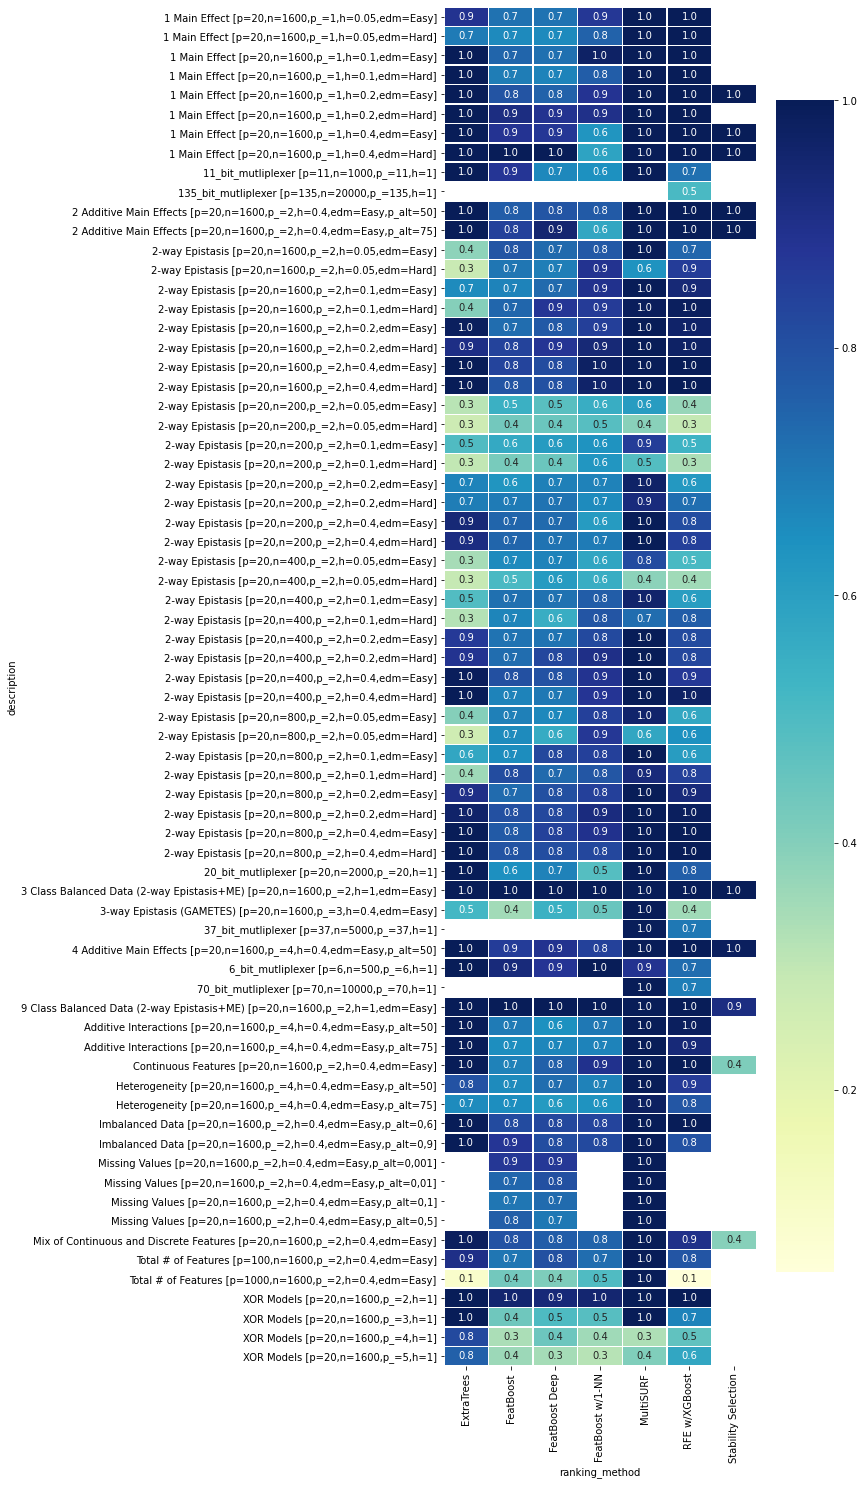

In [2]:
print('computing f1 max/mean')
import time
s = time.time()
max_f1 = statdata.groupby(['description', 'ranking_method', 'replica_no']).agg({'f1': 'max'})
d = time.time() - s
print('computed f1 max in {}'.format(d))
mean_f1 = max_f1.reset_index().groupby(['description', 'ranking_method']).agg({'f1': 'mean'})
maxmean = mean_f1.reset_index()
d = time.time() - s
print('computed f1 mean in {}'.format(d))
import seaborn as sns
import matplotlib.pyplot as plt
rectangular = pd.pivot_table(maxmean,\
    values='f1',\
    index=['description'],\
    columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 25))
plt.yticks(rotation=0)
plt.xticks(rotation=0)
ax = sns.heatmap(rectangular, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu", yticklabels=True, ax=ax)

(157038, 20)


Text(0.5, 1.0, 'recall per ranking method for all datasets')

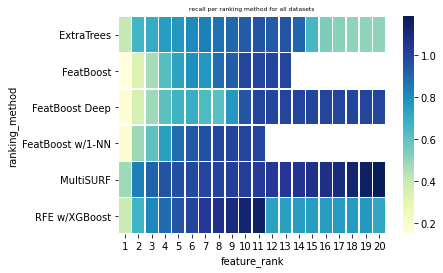

In [17]:
print(statdata.shape)
descr = '1 Main Effect [p=20,n=1600,h=0.05,edm=Easy]'
subset = statdata
# subset = subset[subset['description'] == descr]
subset = subset[subset['feature_rank'] <= 20]
subset = subset[subset['ranking_method'] != 'Stability Selection']

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
rectangular = pd.pivot_table(subset,\
    values='recall',\
    index=['ranking_method'],\
    columns=['feature_rank'])
g = sns.heatmap(rectangular,\
    linewidths=.5, cmap="YlGnBu")
plt.yticks(rotation=0)
plt.xticks(rotation=0)
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x) + 1))
plt.title('recall per ranking method for {}'.format(
    'all datasets'
    # descr\
    ))

Construct a sensible subset for plotting

In [55]:
subset = statdata.copy()
for dataset, data in statdata.groupby('description'):
    all_replicas = data.groupby('replica_no')
    if len(all_replicas.count()) != 24: # only 'finished' datasets
        subset = subset[subset['description'] != dataset]
    else: # add newline in plot title
        descr = dataset.replace(' [p=', '\n[p=')
        descr = descr.replace(',h=', ',\nh=')
        subset = subset.replace({ 'description': dataset }, descr)
        # short_descr = '[p=' + dataset.split(' [p=')[1]
        # entries = subset[subset['description'] == dataset]
        # subset.loc[entries.index, 'short_descr'] = short_descr
subset = subset[subset['feature_rank'] <= 20]
subset = subset[subset['ranking_method'] != 'Stability Selection']
subset.shape

(89214, 20)

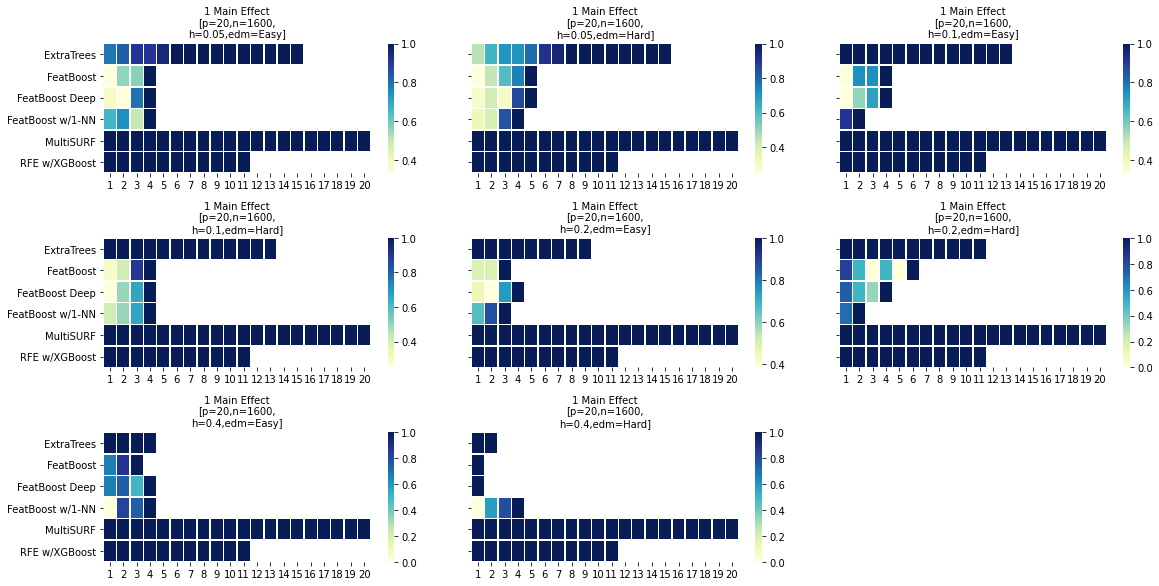

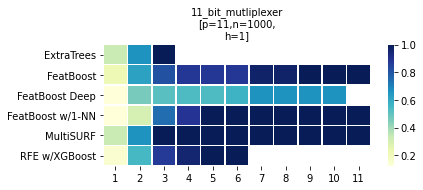

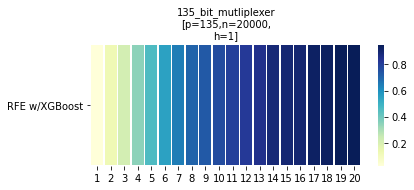

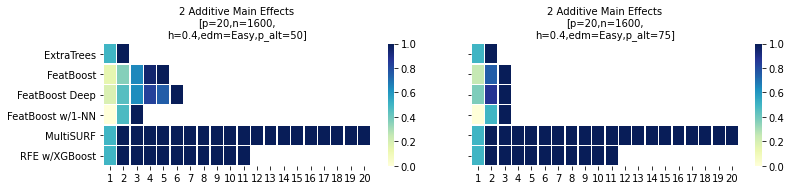

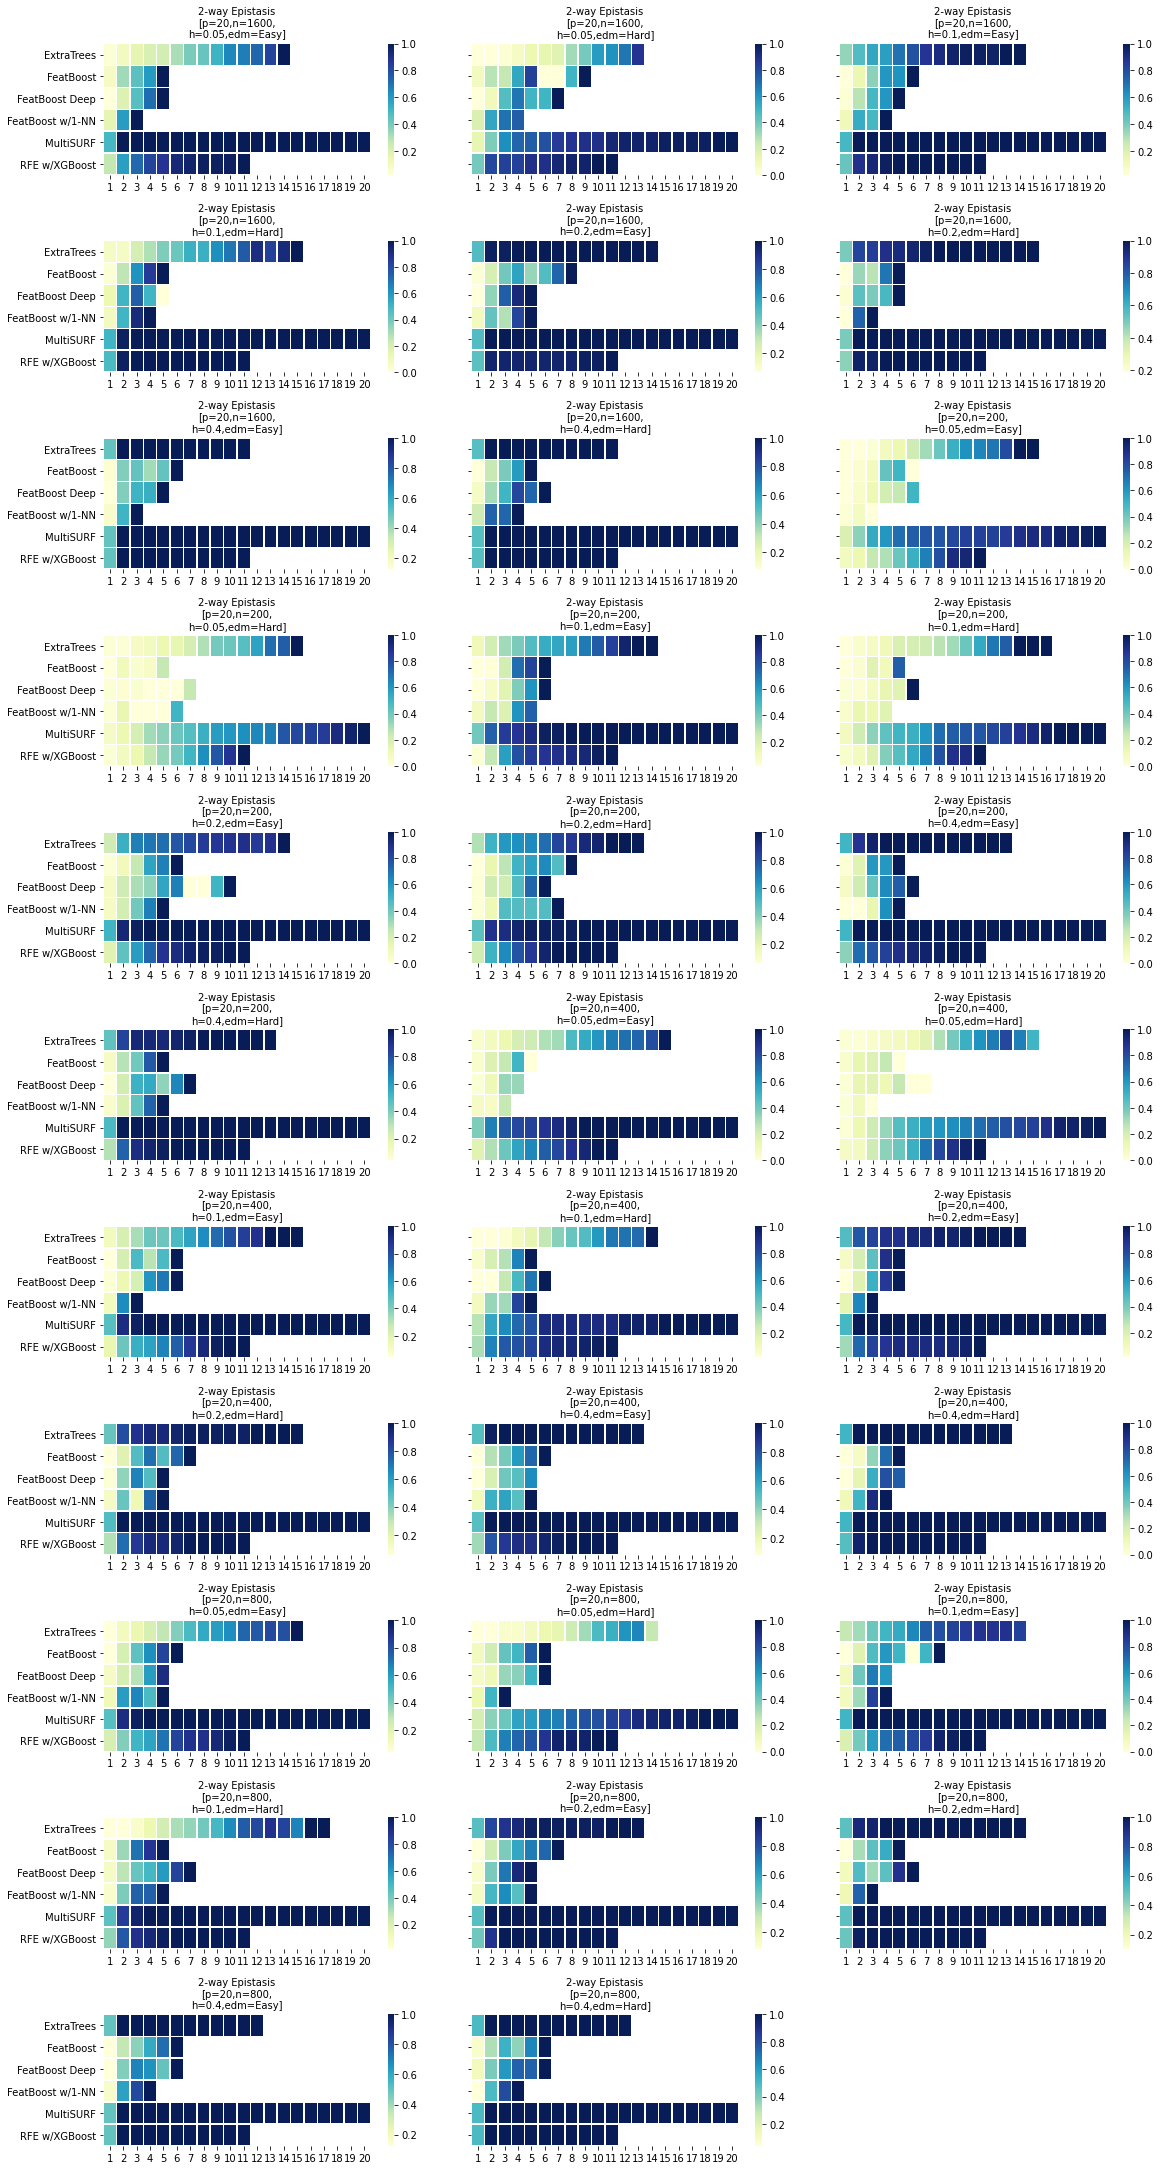

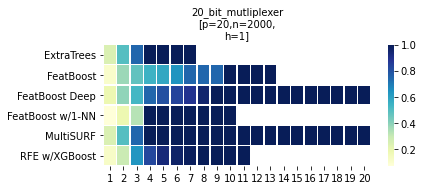

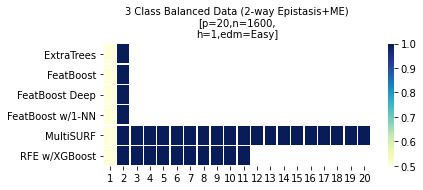

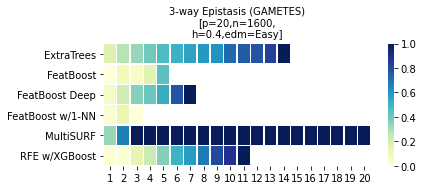

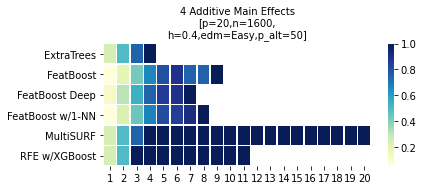

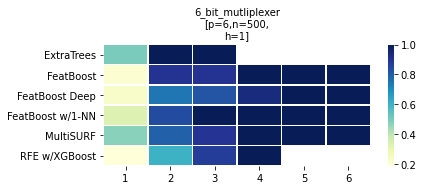

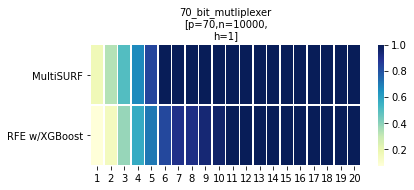

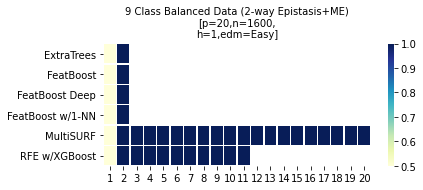

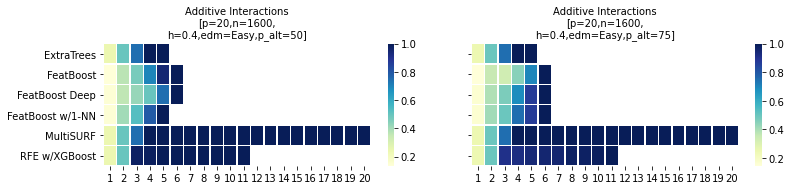

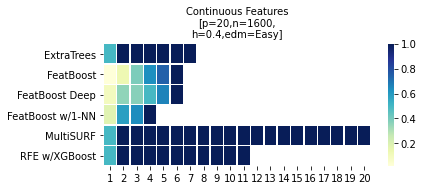

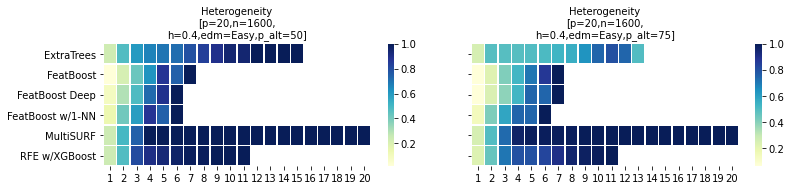

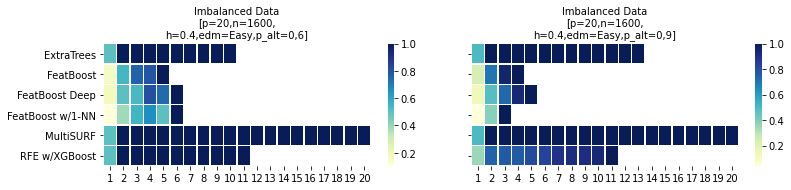

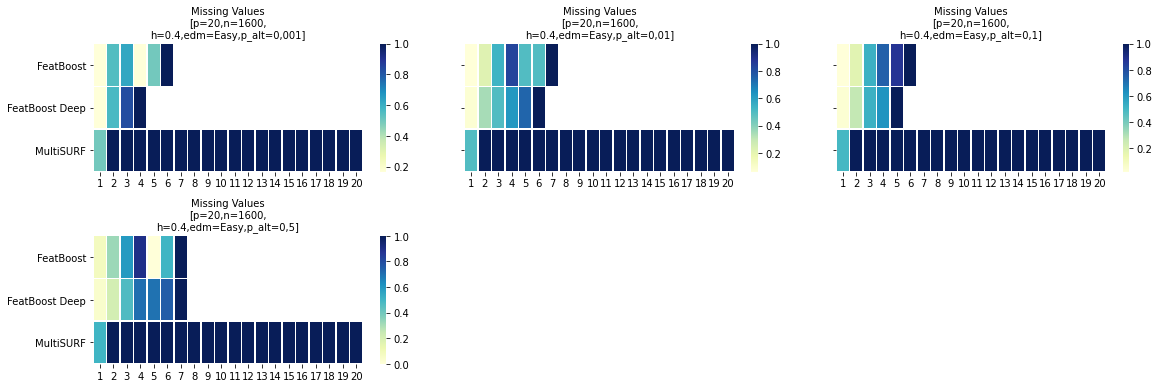

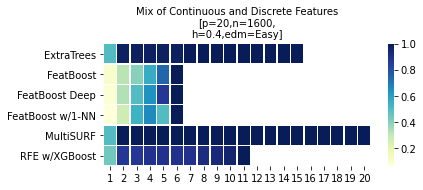

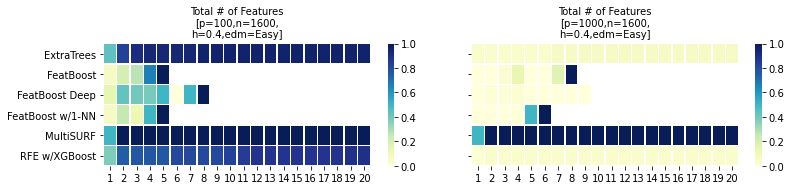

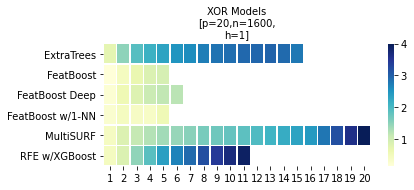

In [60]:
def draw_heatmap(*args, **kwargs):
    data = kwargs.pop('data')
    rect = pd.pivot_table(data, values='recall',\
                        index=['ranking_method'],\
                        columns=['feature_rank'])
    sns.heatmap(rect, linewidths=.5, cmap="YlGnBu")
    plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x) + 1))
    plt.yticks(rotation=0)
    plt.xticks(rotation=0)

def pltrecall(data, title):
    fg = sns.FacetGrid(data, col='description', sharex=False, col_wrap=3, size=2.75, aspect=2)
    fg.map_dataframe(draw_heatmap).set_titles("{col_name}")
    fg.fig.subplots_adjust(wspace=0.1, hspace=0.5)
    # plt.subplots_adjust(top=0.875)
    # fg.fig.suptitle(title)
    # fg.fig.tight_layout()

for name, data in subset.groupby('name'):
    pltrecall(data, name)